# Análisis Exploratorio de Datos (EDA) - **“Sistema predictivo de la intención declarada de estudiar en áreas de Informática / Tecnología / Programación / Ciencia de Datos según factores socioeducativos, actitudinales y de preferencias en jóvenes argentinos de 16 a 18 años que piensan seguir estudiando”**
## Autor: Mauricio Turdo
## Carrera: Tecnicatura Superior en Ciencia de Datos e Inteligencia Artificial

Fuente de Datos para Este proyecto Actitud de la juventud hacia las profesiones STEM  
https://www.argentina.gob.ar/sites/default/files/informe_preliminar_jovenes_stem.pdf

### Conjunto de datos

| Campo | Detalle |
| :--- | :--- |
| **Nombre** | Actitud de los jóvenes hacia las profesiones STEM |
| **Organismo** | IDES-KNAC para el MINCyT |
| **Período de relevamiento** | Del 17 de julio al 19 de agosto de 2023 |
| **Fuente** | Portal oficial `argentina.gob.ar` (formato CSV).
https://www.argentina.gob.ar/node/497059 |
| **Formato** | Archivo tabular (CSV) |
| **Dimensiones iniciales** | 2.891 registros y 217 columnas |
| **Licencia** | Uso público sujeto a reconocimiento de autoría y comunicación previa por escrito |

### Contenido del Documento
1. Introducción y Objetivos
2. Carga del Dataset y Verificación
3. Delimitación Poblacional   
4. Definición de la Variable Objetivo   
5. Análisis de Variables y Depuración
6. Partición de Datos
7. Diagnóstico y Tratamiento de Valores Nulos
8. Esquema de Transformaciones y Pipeline   
9. Análisis y Ranking de Correlación
10. Exportación de archivos (intermedios y matriz final)






**Cómo ejecutarla:** en el repositorio, con el CSV en `data/raw/`. En Colab, subir el CSV a `/content/` (panel de archivos de la izquierda) y ejecutar de arriba hacia abajo.

## 1. Introducción y Objetivos
El propósito de este notebook es realizar un Análisis Exploratorio de Datos (EDA) sobre el dataset seleccionado, documentando cada etapa del preprocesamiento, detección de anomalías y análisis estadístico para fundamentar las decisiones tomadas de cara a futuras etapas de modelado.

In [ ]:
# 1. Librerías de manipulación de datos y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (7, 4.5)
plt.rcParams['figure.dpi'] = 80
import os

## 2. Carga del Dataset y verificación

In [ ]:
# Raíz del proyecto: '..' si la notebook está en notebooks/; '.' si se ejecuta desde la raíz o en Colab
raiz = '..' if os.path.exists('../data/raw') else '.'

# El CSV está en data/raw/ (repositorio) o en /content/ (Colab)
ruta = f'{raiz}/data/raw/estudio_stem_usuaria.csv'
if not os.path.exists(ruta):
    ruta = '/content/estudio_stem_usuaria.csv'

df = pd.read_csv(ruta)

print("--- DIMENSIONES DEL DATASET ---")
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}\n")

# Verificación de calidad y consistencia
print("--- VERIFICACIÓN DE CALIDAD DE DATOS ---")
print(f"Registros duplicados totales: {df.duplicated().sum()}")
print(f"IDs únicos en el dataset: {df['ID'].nunique()} (Total filas: {len(df)})")
print(f"Valores nulos globales en la tabla original: {df.isnull().sum().sum()}")

print("\n--- PRIMEROS REGISTROS ---")
display(df.head())
print("\n--- INFORMACION DEL DATASET ---")
df.info()

--- DIMENSIONES DEL DATASET ---
Filas: 2891 | Columnas: 217

--- VERIFICACIÓN DE CALIDAD DE DATOS ---
Registros duplicados totales: 0
IDs únicos en el dataset: 2891 (Total filas: 2891)
Valores nulos globales en la tabla original: 219845

--- PRIMEROS REGISTROS ---


,ID,F1.Edad,REGION,F4.SEXO,P2_a,P2_b,P2_c,P2_d,P2_e,P2_f,...,P33a,P33b,P33c,P35,P36,P37,P38,P39,P39a,POND_SIN_ELEVAR
0,4,18,2,1,4,3,2,3,1,1,...,3,2,1,1,3.0,3.0,2,1,1.0,1.763319
1,6,16,5,1,2,4,4,4,3,2,...,7,1,4,1,3.0,3.0,1,2,NaN,0.505173
2,19,16,1,1,2,3,3,2,2,2,...,4,2,2,2,2.0,5.0,2,2,NaN,0.330690
3,32,18,5,1,2,3,4,2,2,2,...,5,3,2,2,5.0,4.0,3,2,NaN,0.505173
4,36,17,1,1,1,3,2,2,3,3,...,5,3,2,2,5.0,4.0,3,2,NaN,0.330690



--- INFORMACION DEL DATASET ---
<class 'pandas.DataFrame'>
RangeIndex: 2891 entries, 0 to 2890
Columns: 217 entries, ID to POND_SIN_ELEVAR
dtypes: float64(103), int64(114)
memory usage: 4.8 MB


### Descripción de la Carga de Datos

* Dimensiones de la Tabla: 2.891 observaciones y 217 variables.
* Tipos de Datos:
  * 114 variables de tipo entero (`int64`).
  * 103 variables de tipo flotante (`float64`).
* Uso de Memoria: 4.8 MB.


La muestra es **online y no probabilística (por cuotas)**: los resultados describen a esta muestra y no a todos los jóvenes del país. La ficha técnica indica 2.880 casos y el CSV tiene 2.891; la diferencia no está explicada en la documentación.

## 3. Delimitación de la población de estudio

`P12` pregunta *"¿Pensás continuar tus estudios al terminar la escuela?"* (1 = sí, 2 = ya arranqué, 3 = no, 4 = no sé todavía). Es la **intención de seguir estudiando**, no la situación escolar actual.
El cuestionario aplicó el bloque de intenciones vocacionales (`P13`) solo a quienes respondieron `P12 = 1` o `2`; por eso conservamos esos registros.

De los **505 registros excluidos**: 408 respondieron `P12 = 4` (no saben todavía si seguirán estudiando), 68 respondieron que no y 29 no respondieron.
El filtro reduce el dataset de 2.891 a **2.386 registros**.

In [ ]:
# --- DELIMITACIÓN DE LA POBLACIÓN DE ESTUDIO ---

# 1. Verificar distribución original de P12
print("--- DISTRIBUCIÓN ORIGINAL DE P12 ---")
print(df['P12'].value_counts(dropna=False).sort_index())

# 2. Aplicar criterio de selección
df_filtrado = df[
    df['P12'].isin([1.0, 2.0])].copy()

# 3. Verificar dimensiones
print("\n--- RESULTADO DEL FILTRADO ---")
print(f"Registros originales: {len(df)}")
print(f"Registros seleccionados: {len(df_filtrado)}")
print(f"Registros excluidos: {len(df) - len(df_filtrado)}")

# 4. Verificar respuestas de la variable objetivo original
print("\n--- VERIFICACIÓN DE P13_9 ---")
print(df_filtrado['P13_9'].value_counts(dropna=False))

print("\nValores faltantes en P13_9:",
    df_filtrado['P13_9'].isna().sum())

# 5. Validaciones de consistencia
assert len(df_filtrado) == 2386, ("La cantidad de registros seleccionados no coincide "
    "con el resultado esperado.")
assert df_filtrado['P13_9'].notna().all(), (
    "Existen registros sin respuesta en P13_9.")

print("\nValidaciones superadas: población delimitada correctamente.")

--- DISTRIBUCIÓN ORIGINAL DE P12 ---
P12
1.0    2204
2.0     182
3.0      68
4.0     408
NaN      29
Name: count, dtype: int64

--- RESULTADO DEL FILTRADO ---
Registros originales: 2891
Registros seleccionados: 2386
Registros excluidos: 505

--- VERIFICACIÓN DE P13_9 ---
P13_9
2.0    2027
1.0     359
Name: count, dtype: int64

Valores faltantes en P13_9: 0

Validaciones superadas: población delimitada correctamente.


### ¿Los seleccionados cursan el secundario?
Como `P12` no mide la situación escolar, miramos `P4` (1 = asiste, 2 = dejó por un tiempo, 3 = dejó permanentemente, 4 = terminó el secundario).

In [ ]:
print('Situación escolar (P4) de los registros seleccionados:')
print(df_filtrado['P4'].value_counts().sort_index())
print()
print((df_filtrado['P4'].value_counts(normalize=True).sort_index() * 100).round(1))

Situación escolar (P4) de los registros seleccionados:
P4
1    1980
2     103
4     303
Name: count, dtype: int64

P4
1    83.0
2     4.3
4    12.7
Name: proportion, dtype: float64


El 83 % asiste, el 4,3 % dejó por un tiempo y el 12,7 % terminó el secundario. La población se describe entonces como "jóvenes de 16 a 18 años que piensan seguir estudiando, cursen o no el secundario".

#### Análisis de los registros excluidos
Se comparan características demográficas (sexo) entre los 2.386 registros retenidos y los 505 excluidos por el filtro de la variable P12 - **"¿Pensás continuar tus estudios al terminar la escuela?"**.

--- DISTRIBUCIÓN POR SEXO (%) ---
           Incluidos  Excluidos
Mujer (1)       60.8       36.8
Varón (2)       37.7       61.8
Otro (3)         1.6        1.4

Computadora en el hogar (%):
Incluidos: 65.0 | Excluidos: 50.9


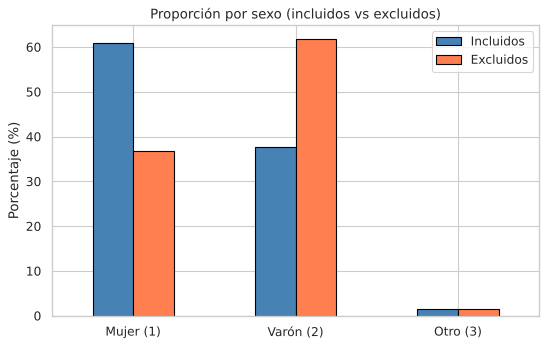

In [ ]:
# --- ANÁLISIS DE LOS 505 REGISTROS EXCLUIDOS POR P12 ---
excluidos = df.drop(df_filtrado.index)

# Distribución por sexo (F4.SEXO: 1 = Mujer, 2 = Varón, 3 = Otro), en %
sexo = pd.DataFrame({
    'Incluidos': df_filtrado['F4.SEXO'].value_counts(normalize=True).sort_index() * 100,
    'Excluidos': excluidos['F4.SEXO'].value_counts(normalize=True).sort_index() * 100}).round(1)
sexo.index = ['Mujer (1)', 'Varón (2)', 'Otro (3)']
print("--- DISTRIBUCIÓN POR SEXO (%) ---")
print(sexo)

# Computadora en el hogar (P32 = 1), en %
print("\nComputadora en el hogar (%):")
print("Incluidos:", round((df_filtrado['P32'] == 1).mean() * 100, 1), "| Excluidos:", round((excluidos['P32'] == 1).mean() * 100, 1))

# Gráfico comparativo por sexo
sexo.plot(kind='bar', color=['steelblue', 'coral'], edgecolor='black')
plt.title('Proporción por sexo (incluidos vs excluidos)')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Análisis de impacto de los registros excluidos
- **Sexo:** entre los excluidos hay más varones (**61,8 %** contra 37,7 % de los incluidos) y menos mujeres (36,8 % contra 60,8 %).
- **Computadora en el hogar:** 50,9 % en los excluidos y 65,0 % en los incluidos.

**Limitación:** el recorte no es neutro. Los resultados valen para quienes piensan seguir estudiando y no para todos los participantes de la encuesta.

### Resultados de la delimitación poblacional

Luego de aplicar el criterio de selección sobre `P12`, se obtuvieron los siguientes resultados:

- **Dataset original:** 2.891 observaciones.
- **Registros seleccionados:** 2.386 observaciones.
- **Registros excluidos:** 505 observaciones.
- **Criterio aplicado:** conservar los registros con `P12 = 1` o `P12 = 2`.
- **Disponibilidad de la variable objetivo:** los registros seleccionados cuentan con respuestas válidas en `P13_9`.

La selección representa aproximadamente el 82,53 % del conjunto de datos original.

Se mantiene esta delimitación porque la pregunta `P13` (de donde sale el objetivo) solo se aplicó a estos registros.

Los resultados del futuro modelo estarán condicionados por este criterio de selección y no representarán necesariamente a todos los participantes de la encuesta.

### 4. Definición de la variable objetivo

La variable objetivo ($y$) es la **intención declarada** de estudiar una carrera de Informática, Tecnología, Programación o Ciencia de Datos. No predice la inscripción futura ni la carrera que efectivamente se cursará.

Se construye a partir de la opción `P13_9`:
* **$y = 1$**: el encuestado seleccionó esa opción.
* **$y = 0$**: el encuestado **no la seleccionó**. Esto **no equivale a rechazarla**: puede haber elegido otras áreas.

**Indecisos:** 267 registros marcaron "No sé aún" (`P13_12`). La indecisión es una respuesta válida y muy relevante en orientación vocacional. Se excluyen **para simplificar el trabajo**, y esto cambia el alcance: el modelo describe a jóvenes que piensan seguir estudiando **y ya eligieron qué estudiar**. Sus resultados **no se pueden generalizar a los jóvenes indecisos**.

In [ ]:
# --- DEFINICIÓN DE LA VARIABLE OBJETIVO ---

# 1. Respuestas de indecisión ("No sé aún", P13_12 = 1)
print("Distribución original de P13_12:")
print(df_filtrado['P13_12'].value_counts(dropna=False))

cantidad_incertidumbre = (df_filtrado['P13_12'] == 1).sum()
porcentaje_con_indecisos = (df_filtrado['P13_9'] == 1).mean() * 100

# 2. Se excluyen los indecisos (sobre una copia: df_filtrado no se modifica)
df_modelado = df_filtrado[df_filtrado['P13_12'] != 1].copy()
print("\nRegistros excluidos por indecisión:", cantidad_incertidumbre)

# 3. Variable objetivo binaria
df_modelado['y'] = (df_modelado['P13_9'] == 1).astype(int)

# 4. Distribución de clases
print("\n--- DISTRIBUCIÓN DE LA VARIABLE OBJETIVO ---")
distribucion = df_modelado['y'].value_counts().sort_index()
print(distribucion.rename({0: 'No (y=0)', 1: 'Sí (y=1)'}))

# 5. Prevalencia simple y ponderada (la ponderada es solo descriptiva)
prev_simple = df_modelado['y'].mean() * 100
prev_ponderada = np.average(df_modelado['y'], weights=df_modelado['POND_SIN_ELEVAR']) * 100
print(f"\nPrevalencia positiva sin ponderar: {prev_simple:.2f}%")
print(f"Prevalencia positiva ponderada: {prev_ponderada:.2f}%")
print(f"Prevalencia incluyendo a los indecisos: {porcentaje_con_indecisos:.2f}%")
print("\nTotal de registros para el modelado:", len(df_modelado))

Distribución original de P13_12:
P13_12
2.0    2119
1.0     267
Name: count, dtype: int64

Registros excluidos por indecisión: 267

--- DISTRIBUCIÓN DE LA VARIABLE OBJETIVO ---
y
No (y=0)    1760
Sí (y=1)     359
Name: count, dtype: int64

Prevalencia positiva sin ponderar: 16.94%
Prevalencia positiva ponderada: 19.75%
Prevalencia incluyendo a los indecisos: 15.05%

Total de registros para el modelado: 2119


### Análisis de la distribución de la variable objetivo
Tras excluir a los indecisos quedan **2.119 observaciones**:
- **`y = 0`:** 1.760 jóvenes que no seleccionaron `P13_9` (eligieron otras áreas u otras preferencias; no es un rechazo).
- **`y = 1`:** 359 jóvenes que declaran intención de estudiar Informática, Tecnología, Programación o Ciencia de Datos.

La clase positiva es el **16,94 %** y la negativa el 83,06 %: hay desbalance. Por eso la exactitud no alcanza como única métrica y se analizan también precisión, recall, F1 y ROC-AUC.

Las estimaciones ponderadas se usan solo como información descriptiva: con el ponderador de la encuesta la prevalencia positiva es 19,75 %, y si se incluyera a los indecisos sería 15,05 %.

## 5. Análisis exploratorio y selección de variables predictoras

Cada grupo de variables se excluye por un motivo distinto:

1. **Identificador y ponderador** (`ID`, `POND_SIN_ELEVAR`): no explican al estudiante. El ponderador se reserva para descripciones.
2. **Filtro y objetivo** (`P12`, `P13_1` a `P13_12`): definen la población y el objetivo.
3. **Fuga de información** (`P15`, `P16`, `P18`): dependen de la respuesta objetivo (se muestra la evidencia abajo).
4. **Condicionales y de baja frecuencia** (`P39`, `P39a`): solo 54 de 2.119 jóvenes (2,5 %) tienen hijos, y P39a (cuántos hijos) únicamente la responden ellos. Casi no varían, así que aportan poca información.
5. **Definición poco clara en el diccionario** (`P33b`, `P33c`): no usamos variables cuyo significado no podemos respaldar. Se conserva `P33a` (integrantes del hogar).

**Evidencia de la fuga:** si una pregunta la responden solo los que eligieron (o no) informática, el modelo "adivinaría" el resultado.

In [ ]:
p15e = [c for c in df.columns if c.startswith('P15e_')]
p16 = [c for c in df.columns if c.startswith('P16_')]
p18 = [c for c in df.columns if c.startswith('P18_')]

for valor in [1, 0]:
    grupo = df_modelado[df_modelado['y'] == valor]
    print(f"y={valor} ({len(grupo)} casos): responden P15e {grupo[p15e].notna().any(axis=1).sum()} | responden P16 {grupo[p16].notna().any(axis=1).sum()}")

print("\nP18: responden en el modelado:", df_modelado[p18].notna().any(axis=1).sum(), "| responden entre los excluidos por P12:", excluidos[p18].notna().any(axis=1).sum(), "de", len(excluidos))

y=1 (359 casos): responden P15e 359 | responden P16 0
y=0 (1760 casos): responden P15e 0 | responden P16 1027

P18: responden en el modelado: 0 | responden entre los excluidos por P12: 505 de 505


**Lectura:** `P15e` la responden **todos** los de y = 1 y **ninguno** de y = 0. `P16` la responden solo los de y = 0 (1.027 de 1.760). `P18` solo la contestaron los excluidos por `P12`. Por eso se excluyen.

**Importante:** una correlación alta con el objetivo **no** prueba fuga. Variables como `P3_d`, `P27` y `P11_*` se evalúan en la sección 9 según lo que miden.

### Códigos especiales (según el diccionario)
Algunos números no son respuestas reales:
- `P5`, `P6`, `P7` (letras d, e, f): código **5** (`P5`) o **6** (`P6`, `P7`) = *"No tengo estas materias"*.
- `P36`, `P37`: código **6** = *"No sé"* el nivel educativo de los padres.
- `P27`: código **99** = *"Ns/Nc"*. Es una respuesta propia y **se conserva como una categoría más**.

In [ ]:
especiales = [('P5_d', 5), ('P5_e', 5), ('P5_f', 5), ('P6_d', 6), ('P6_e', 6), ('P6_f', 6),
              ('P7_d', 6), ('P7_e', 6), ('P7_f', 6), ('P36', 6), ('P37', 6), ('P27', 99)]
for variable, codigo in especiales:
    print(f"{variable} = {codigo}: {(df_modelado[variable] == codigo).sum()} casos")

print("\n% que elige informática (y=1) según tenga o no la materia:")
for variable, codigo in [('P5_d', 5), ('P6_d', 6), ('P7_d', 6)]:
    sin = df_modelado[df_modelado[variable] == codigo]['y'].mean() * 100
    con = df_modelado[df_modelado[variable] != codigo]['y'].mean() * 100
    print(f"  {variable}: sin la materia {sin:.1f}% | con la materia {con:.1f}%")

P5_d = 5: 466 casos


P5_e = 5: 199 casos
P5_f = 5: 116 casos
P6_d = 6: 605 casos
P6_e = 6: 329 casos
P6_f = 6: 167 casos
P7_d = 6: 705 casos
P7_e = 6: 441 casos
P7_f = 6: 230 casos
P36 = 6: 101 casos
P37 = 6: 100 casos
P27 = 99: 13 casos

% que elige informática (y=1) según tenga o no la materia:
  P5_d: sin la materia 13.3% | con la materia 18.0%
  P6_d: sin la materia 13.4% | con la materia 18.4%
  P7_d: sin la materia 12.6% | con la materia 19.1%


**Decisión:** para cada código se crea un **indicador 0/1** (`no_tiene_*`, `no_sabe_*`) y el valor pasa a vacío para que no se lea como una nota. Se hace porque no tener la materia se relaciona con el objetivo (por ejemplo 13,3 % vs 18,0 % en `P5_d`).

### Vacíos y `P38`

In [ ]:
# Saltos del cuestionario
print("P20 vacío si P19=2 (no conoce a nadie):", df_modelado[df_modelado['P19'] == 2]['P20'].isna().sum(), "de", (df_modelado['P19'] == 2).sum())
print("P20 vacío si P19=1 (conoce a alguien):", df_modelado[df_modelado['P19'] == 1]['P20'].isna().sum(), "de", (df_modelado['P19'] == 1).sum())
print("P24 vacío si P4 distinto de 1 (no asiste):", df_modelado[df_modelado['P4'] != 1]['P24'].isna().sum(), "de", (df_modelado['P4'] != 1).sum())
print("P24 vacío si P4=1 (asiste):", df_modelado[df_modelado['P4'] == 1]['P24'].isna().sum(), "de", (df_modelado['P4'] == 1).sum())

# P38: habitaciones para dormir
print("\nP38, valores más altos:", df_modelado['P38'].sort_values(ascending=False).head(8).tolist())
print("Máximo de integrantes del hogar (P33a):", int(df_modelado['P33a'].max()))

P20 vacío si P19=2 (no conoce a nadie): 1272 de 1272
P20 vacío si P19=1 (conoce a alguien): 0 de 847
P24 vacío si P4 distinto de 1 (no asiste): 373 de 373
P24 vacío si P4=1 (asiste): 0 de 1746

P38, valores más altos: [50, 50, 43, 26, 19, 13, 12, 11]
Máximo de integrantes del hogar (P33a): 7


**Tipos de vacíos y tratamiento**

| Tipo | Variables | Qué significa | Tratamiento |
|---|---|---|---|
| Salto del cuestionario | `P20`, `P24` | No les tocaba responder (el diccionario lo marca con −99) | Se completa con 0 = *"no corresponde"* y se codifica como categoría. **Solo aquí** ese significado es correcto. |
| Respuesta desconocida | `P36`, `P37` = 6 | Respondió "No sé" | Indicador `no_sabe_*` + vacío imputado con la mediana |
| No tiene la materia | `P5`, `P6`, `P7` (d, e, f) | La escuela no la dicta | Indicador `no_tiene_*` + vacío imputado con la mediana |
| Salto con muchos vacíos | `P25`, `P21` | 82 % y 60 % de vacíos | Se descartan del pipeline |

**`P38` (habitaciones para dormir):** el diccionario **no define un rango**. Como referencia, el hogar más grande tiene 7 integrantes. Los valores 19, 26, 43, 50 y 50 son imposibles como cantidad de habitaciones para dormir, así que el umbral es **15** y solo **5 casos** pasan a vacío. Los valores entre 10 y 14 se conservan porque no se pueden comprobar como error.

In [ ]:
# --- TRATAMIENTO DE CÓDIGOS ESPECIALES Y CONSTRUCCIÓN DE X e y ---
# Se trabaja sobre una copia (df_tratado): así la celda se puede ejecutar varias veces sin alterar los datos.
LIMITE_P38 = 15
df_tratado = df_modelado.copy()

# 1. P5_d, P5_e y P5_f (Código 5: "No tengo la materia")
for letra in ['d', 'e', 'f']:
    columna = f'P5_{letra}'
    df_tratado[f'no_tiene_{columna}'] = (df_tratado[columna] == 5).astype(int)
    df_tratado[columna] = df_tratado[columna].replace(5, np.nan)

# 2. P6 y P7 (Código 6: "No tengo estas materias")
for prefijo in ['P6', 'P7']:
    for letra in ['d', 'e', 'f']:
        columna = f'{prefijo}_{letra}'
        df_tratado[f'no_tiene_{columna}'] = (df_tratado[columna] == 6).astype(int)
        df_tratado[columna] = df_tratado[columna].replace(6, np.nan)

# 3. P36 y P37 (Código 6: "No sé")
for columna in ['P36', 'P37']:
    df_tratado[f'no_sabe_{columna}'] = (df_tratado[columna] == 6).astype(int)
    df_tratado[columna] = df_tratado[columna].replace(6, np.nan)

# 4. P27: el código 99 (Ns/Nc) se conserva como categoría

# 5. P38: valores de 15 o más habitaciones pasan a NaN
df_tratado.loc[df_tratado['P38'] >= LIMITE_P38, 'P38'] = np.nan

# 6. Columnas a excluir
columnas_a_excluir = ['ID', 'POND_SIN_ELEVAR', 'P12', 'P33b', 'P33c']
columnas_a_excluir += [f'P13_{i}' for i in range(1, 13)]
columnas_a_excluir += [col for col in df_tratado.columns if col.startswith(('P15', 'P16', 'P18', 'P39'))]

# 7. Construcción de X e y
features_candidatas = [col for col in df_tratado.columns if col not in columnas_a_excluir + ['y']]
X = df_tratado[features_candidatas].copy()
y = df_tratado['y'].copy()

print("Columnas originales:", df.shape[1], "| excluidas:", len(columnas_a_excluir), "| candidatas:", df.shape[1] - len(columnas_a_excluir))
print("Indicadores creados:", len([c for c in X.columns if c.startswith(('no_tiene_', 'no_sabe_'))]))
print(f"Variables predictoras (X): {X.shape[1]} columnas | Registros: {len(X)}")

Columnas originales: 217 | excluidas: 101 | candidatas: 116
Indicadores creados: 11
Variables predictoras (X): 127 columnas | Registros: 2119


### Resultado de la depuración
- Se excluyeron **101 columnas**: 2 de identificación y ponderador, 13 de filtro y objetivo (`P12`, `P13_*`), 82 de `P15`/`P16`/`P18`, 2 de `P39`/`P39a` y 2 de `P33b`/`P33c`.
- Quedan 116 candidatas, más 11 indicadores creados: **127 columnas en `X`**.
- `X` (predictores) e `y` (objetivo) quedan separados, y `ID` y el ponderador no están en `X`.

## 6. Partición de Datos

In [ ]:
from sklearn.model_selection import train_test_split

# Partición estratificada (80/20) sobre el dataset ya depurado y con códigos especiales tratados
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Entrenamiento (X_train): {X_train.shape}")
print(f"Evaluación (X_test): {X_test.shape}")
print(f"Prevalencia de y=1 en entrenamiento: {y_train.mean() * 100:.2f}% | en prueba: {y_test.mean() * 100:.2f}%")

Entrenamiento (X_train): (1695, 127)
Evaluación (X_test): (424, 127)
Prevalencia de y=1 en entrenamiento: 16.93% | en prueba: 16.98%


## 7. Diagnóstico y Tratamiento de Valores Nulos

In [ ]:
nulos_df = pd.DataFrame({
    'Cantidad_Nulos': X.isnull().sum(),
    'Porcentaje_Nulos': (X.isnull().mean() * 100).round(2)})

nulos_df = nulos_df[nulos_df['Cantidad_Nulos'] > 0].sort_values(by='Porcentaje_Nulos', ascending=False)

print(f"\n--- Resultado del Diagnóstico: Total de variables con valores nulos: {len(nulos_df)} ---")
print(nulos_df.to_string())


--- Resultado del Diagnóstico: Total de variables con valores nulos: 16 ---
      Cantidad_Nulos  Porcentaje_Nulos
P25             1746             82.40
P20             1272             60.03
P21             1272             60.03
P7_d             705             33.27
P6_d             605             28.55
P5_d             466             21.99
P7_e             441             20.81
P24              373             17.60
P6_e             329             15.53
P7_f             230             10.85
P5_e             199              9.39
P6_f             167              7.88
P5_f             116              5.47
P36              104              4.91
P37              104              4.91
P38                5              0.24


### Diagnóstico de valores faltantes
Sobre las **2.119 observaciones y 127 variables predictoras** hay **16 variables con vacíos**. Las principales:
* **`P25`** (82,40 %) y **`P20` / `P21`** (60,03 %): son saltos del cuestionario. `P25` y `P21` se descartan del pipeline; `P20` se conserva como categoría nominal.
* **`P24`** (17,60 %): salto del cuestionario (solo la responden quienes asisten).
* **`P5`, `P6`, `P7`**: vacíos creados al tratar el código "no tengo la materia".
* **`P36` y `P37`**: vacíos creados al tratar el código "No sé".
* **`P38`**: 5 valores imposibles pasados a vacío.

Los vacíos no son errores de carga: la mayoría responde a la lógica del cuestionario (ver la tabla de la sección 5).

### Criterio de tratamiento (dentro del pipeline)
* **Numéricas y ordinales:** mediana y estandarización.
* **Nominales:** constante `0`, seguida de *One-Hot*. Los únicos nominales con vacíos son `P20` y `P24`, donde el vacío **sí** significa "no corresponde".
* **Binarias e indicadores:** categoría más frecuente (moda).

Para evitar la fuga de información, los parámetros se calculan solo con `X_train` y luego se aplican a `X_test`.

## 8. Esquema de Transformaciones y Pipeline
Para preparar las variables antes de aplicar el modelo de Regresión Logística, se diseñó un esquema de transformación mediante `ColumnTransformer` y subprocesos `Pipeline`.

| Tipo de variable | Ejemplos | Transformación | Fundamento |
| :--- | :--- | :--- | :--- |
| **Binarias** | P8, P9, P19, P22, P23, P26, P31, P32 | Recodificación 1/2 a 1/0 e imputación | Facilita la interpretación de las respuestas binarias. |
| **Ordinales** | P2, P3, P5, P6, P7, P36, P37 | Imputación por mediana y estandarización | Conserva el orden natural de las categorías. |
| **Nominales** | REGION, F4.SEXO, P4, P10, P11, P20, P24, P27, P28, P35 | Imputación con constante 0 y `OneHotEncoder` | Evita asignar un orden artificial a categorías sin jerarquía. |
| **Numéricas** | F1.Edad, P33a, P38 | Imputación por mediana y estandarización | Permite trabajar con variables de distinta escala. |

**Prevención de fuga de datos (data leakage):** los parámetros de imputación, codificación y escalado se ajustan exclusivamente con `X_train`. Luego, las mismas transformaciones se aplican a `X_test`, sin volver a ajustarlas.

In [ ]:
# --- ESQUEMA DE TRANSFORMACIONES Y PIPELINE ---
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 0. Se descartan P25 y P21 (vacíos por saltos del cuestionario)
X_train = X_train.drop(columns=['P25', 'P21'])
X_test = X_test.drop(columns=['P25', 'P21'])

# 1. CLASIFICACIÓN DE LAS VARIABLES
variables_ordinales = [col for col in X_train.columns
    if col.startswith(('P2_', 'P3_', 'P5_', 'P6_', 'P7_')) or col in ['P36', 'P37']]

variables_nominales = ['REGION', 'F4.SEXO', 'P4', 'P27', 'P28', 'P35', 'P20', 'P24',
    'P10_a', 'P10_b', 'P10_c', 'P10_d', 'P10_e', 'P10_f', 'P10_g',
    'P11_a', 'P11_b', 'P11_c', 'P11_d', 'P11_e']

variables_numericas = ['P33a', 'P38', 'F1.Edad']

variables_binarias_originales = [col for col in X_train.columns
    if col.startswith(('P8_', 'P9_', 'P22_')) or col in ['P19', 'P23', 'P26', 'P31', 'P32']]

variables_indicadoras = [col for col in X_train.columns
    if col.startswith(('no_tiene_', 'no_sabe_'))]

variables_binarias = variables_binarias_originales + variables_indicadoras

# 2. VALIDACIÓN: todas las columnas quedan clasificadas, una sola vez
columnas_clasificadas = variables_ordinales + variables_nominales + variables_numericas + variables_binarias
sin_tratar = [col for col in X_train.columns if col not in columnas_clasificadas]
duplicadas = [col for col in set(columnas_clasificadas) if columnas_clasificadas.count(col) > 1]

assert not sin_tratar, f"Hay variables sin clasificar: {sin_tratar}"
assert not duplicadas, f"Hay variables clasificadas más de una vez: {duplicadas}"
print("Clasificación de variables validada correctamente.")

# 3. RECODIFICACIÓN DE VARIABLES BINARIAS (1/2 a 1/0)
for col in variables_binarias_originales:
    X_train[col] = X_train[col].replace({1: 1, 2: 0})
    X_test[col] = X_test[col].replace({1: 1, 2: 0})
print("Variables binarias recodificadas.")

# 4. SUBPIPELINES DE TRANSFORMACIÓN
transformador_num_ord = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='median')),
    ('escalador', StandardScaler())])

transformador_nominal = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='constant', fill_value=0)),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

transformador_binario = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='most_frequent'))])

# 5. COLUMNTRANSFORMER
preprocesador = ColumnTransformer(transformers=[
        ('num_ord', transformador_num_ord, variables_ordinales + variables_numericas),
        ('nominales', transformador_nominal, variables_nominales),
        ('binarias', transformador_binario, variables_binarias)], remainder='drop')

# 6. AJUSTE (solo con entrenamiento) Y TRANSFORMACIÓN
X_train_prep_array = preprocesador.fit_transform(X_train)
X_test_prep_array = preprocesador.transform(X_test)

# Nombres de las columnas generadas
feature_names = preprocesador.get_feature_names_out()

# Conversión a DataFrames conservando el índice original
X_train_prep = pd.DataFrame(X_train_prep_array, columns=feature_names, index=X_train.index)
X_test_prep = pd.DataFrame(X_test_prep_array, columns=feature_names, index=X_test.index)

# 7. CONTROLES
assert X_train_prep.isna().sum().sum() == 0 and X_test_prep.isna().sum().sum() == 0
assert list(X_train_prep.columns) == list(X_test_prep.columns)
print(f"\nVariables de entrada al pipeline: {X_train.shape[1]}")
print(f"X_train_prep: {X_train_prep.shape} | X_test_prep: {X_test_prep.shape} | valores faltantes: 0")

Clasificación de variables validada correctamente.
Variables binarias recodificadas.

Variables de entrada al pipeline: 125
X_train_prep: (1695, 208) | X_test_prep: (424, 208) | valores faltantes: 0


El preprocesamiento se realizó sobre las **125 variables** predictoras que ingresan al pipeline (tras descartar `P25` y `P21`, que son saltos del cuestionario con muchos vacíos).

El desglose de las características transformadas es:
* **31 variables ordinales:** imputación por mediana y estandarización.
* **20 variables nominales:** imputación por constante fija (`0`, "no corresponde") y codificación One-Hot.
* **3 variables numéricas:** imputación por mediana y estandarización.
* **60 variables binarias originales:** recodificación de $1/2$ a $1/0$ e imputación por moda.
* **11 indicadores de códigos especiales:** incorporación de flags binarias (`no_tiene_*` y `no_sabe_*`) para preservar patrones específicos de omisión estructural o incertidumbre.

Como resultado de la codificación One-Hot, la matriz predictora final quedó conformada por **208 columnas**.

La división de los datos produjo:
* **Entrenamiento:** 1.695 registros.
* **Prueba:** 424 registros.

Se evitó la fuga de información (*data leakage*) garantizando que el ajuste de todos los transformadores se realizara exclusivamente sobre el conjunto de entrenamiento. Posteriormente, las mismas transformaciones se aplicaron de forma idéntica sobre el conjunto de prueba.

## 9. Análisis y Ranking de Correlación

--- MAYORES CORRELACIONES CON LA VARIABLE OBJETIVO ---

Diez mayores correlaciones positivas:


num_ord__P3_d             0.3916
num_ord__P5_d             0.3175
binarias__P8_3_f          0.2608
nominales__F4.SEXO_2.0    0.2579
nominales__P27_4.0        0.2477
nominales__P11_a_1.0      0.2429
nominales__P11_d_4.0      0.2051
binarias__P22_3           0.1765
num_ord__P7_d             0.1740
num_ord__P3_b             0.1673
Name: y, dtype: float64


Diez mayores correlaciones negativas:


nominales__F4.SEXO_1.0   -0.2501
nominales__P11_d_3.0     -0.2409
nominales__P11_a_3.0     -0.1931
binarias__P8_3_e         -0.1046
nominales__P20_0.0       -0.1042
nominales__P11_e_3.0     -0.0933
binarias__P8_3_h         -0.0883
binarias__P9_3_g         -0.0861
binarias__P8_2_f         -0.0850
num_ord__P5_e            -0.0772
Name: y, dtype: float64

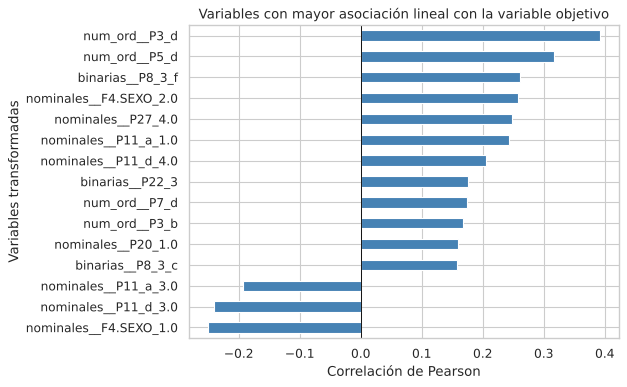


Nota: las correlaciones muestran asociaciones estadísticas, no implican causalidad.


In [ ]:
# 1. Recuperar los nombres de las variables transformadas
nombres_variables = preprocesador.get_feature_names_out()

# 2. Como X_train_prep ya fue creado con index=X_train.index,
# se alinea de forma nativa y perfecta con y_train
df_corr = X_train_prep.copy()

# 3. Incorporar la variable objetivo asegurando la alineación por índice
df_corr['y'] = y_train

# 4. Calcular correlaciones de Pearson
matriz_corr = df_corr.corr()

correlacion_con_y = (matriz_corr['y'].drop('y').dropna())

# 5. Mostrar las variables con mayor asociación positiva y negativa
print("--- MAYORES CORRELACIONES CON LA VARIABLE OBJETIVO ---")

top_positivas = correlacion_con_y.sort_values(ascending=False).head(10)
top_negativas = correlacion_con_y.sort_values(ascending=True).head(10)

print("\nDiez mayores correlaciones positivas:")
display(top_positivas.round(4))
print("\nDiez mayores correlaciones negativas:")
display(top_negativas.round(4))

# 6. Gráfico de las 15 variables con mayor correlación absoluta
top_absolutas = (correlacion_con_y.abs().sort_values(ascending=False)
    .head(15).index)

datos_grafico = correlacion_con_y.loc[top_absolutas].sort_values()
plt.figure(figsize=(8, 5))
datos_grafico.plot(kind='barh', color='steelblue')

plt.title('Variables con mayor asociación lineal con la variable objetivo')
plt.xlabel('Correlación de Pearson')
plt.ylabel('Variables transformadas')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print("\nNota: las correlaciones muestran asociaciones estadísticas, no implican causalidad.")

### Análisis y Ranking de Correlación

**Resultados (entrenamiento):**
* **Asociaciones positivas más altas:** `P3_d` (r = 0,39), `P5_d` (0,32), `P8_3_f`, ser varón (`F4.SEXO_2`), `P27_4` (orientación en Informática) y `P11_a_1`.
* **Asociaciones negativas más altas:** ser mujer (`F4.SEXO_1`, r = −0,25), `P11_d_3` y `P11_a_3`.

**Una correlación alta no prueba fuga ni causalidad.** Para decidir si una variable sirve hay que ver qué pregunta mide y si se conocería al usar el modelo:

| Variable | Qué mide (diccionario) | ¿Se conoce al usar el modelo? |
|---|---|---|
| `P3_d` | Interés en *hacer cursos de programación o robótica* | Sí: es un interés previo, se pregunta aparte de la elección |
| `P27` | Orientación del colegio actual (4 = Informática) | Sí: es un dato del colegio |
| `P11_a`, `P11_d` | Participación en talleres de robótica/programación y tutorías de olimpíadas de informática | Sí: es experiencia previa |

**Conclusión:** no son fuga, pero están **muy cerca del objetivo** (interés o experiencia en programación): hacen más fácil predecir y explican menos sobre otros factores. En el modelado se entrena el modelo **con todas las variables** y se deja como línea futura probarlo **sin `P3_d`, `P5_d`, `P8_3_f` y `P11_*`**.

## 10. Exportación de archivos
Se exportan los archivos necesarios para la etapa de modelado, separados en dos carpetas según su contenido.

In [ ]:
os.makedirs(f'{raiz}/data/interim', exist_ok=True)
os.makedirs(f'{raiz}/data/processed', exist_ok=True)

# data/interim: datos de entrada del pipeline (125 columnas), SIN imputar, escalar ni codificar
# (para usar el preprocesador dentro de un Pipeline con GridSearchCV)
X_train.to_csv(f'{raiz}/data/interim/X_train.csv', index_label='indice_original', encoding='utf-8')
X_test.to_csv(f'{raiz}/data/interim/X_test.csv', index_label='indice_original', encoding='utf-8')

# data/processed: matrices listas para entrenar (pipeline aplicado)
X_train_prep.to_csv(f'{raiz}/data/processed/X_train_prep.csv', index_label='indice_original', encoding='utf-8')
X_test_prep.to_csv(f'{raiz}/data/processed/X_test_prep.csv', index_label='indice_original', encoding='utf-8')
y_train.to_csv(f'{raiz}/data/processed/y_train.csv', index_label='indice_original', encoding='utf-8')
y_test.to_csv(f'{raiz}/data/processed/y_test.csv', index_label='indice_original', encoding='utf-8')

print("interim  : X_train", X_train.shape, "| X_test", X_test.shape)
print("processed: X_train_prep", X_train_prep.shape, "| X_test_prep", X_test_prep.shape, "| y_train", y_train.shape, "| y_test", y_test.shape)

interim  : X_train (1695, 125) | X_test (424, 125)
processed: X_train_prep (1695, 208) | X_test_prep (424, 208) | y_train (1695,) | y_test (424,)


| Archivo | Carpeta | Contenido | Uso |
|---|---|---|---|
| `X_train.csv`, `X_test.csv` | `data/interim` | 1.695 y 424 filas × 125 columnas, sin imputar, escalar ni codificar | Entrada del pipeline, para usarlo dentro de `GridSearchCV` |
| `X_train_prep.csv`, `X_test_prep.csv` | `data/processed` | 1.695 y 424 filas × 208 columnas, sin vacíos | **Matriz final lista para entrenar** |
| `y_train.csv`, `y_test.csv` | `data/processed` | Objetivo de cada partición | Modelado |

**Cómo se obtiene la matriz final:** `X_train.csv` y `X_test.csv` (125 columnas) → pipeline (imputación, escalado y One-Hot ajustados solo con entrenamiento) → `X_train_prep` y `X_test_prep` (208 columnas). Todos los archivos usan `indice_original` para poder cruzarlos. `ID` y `POND_SIN_ELEVAR` no se exportan, así que no pueden mezclarse con los predictores. En Colab, los archivos se descargan desde el panel de archivos de la izquierda.